In [ ]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/sorted_temp_and_rain_dataset.csv')

In [ ]:
df.head(10)

,tem,Month,Year,rain
0,16.9760,1,1901,18.5356
1,19.9026,2,1901,16.2548
2,24.3158,3,1901,70.7981
3,28.1834,4,1901,66.1616
4,27.8892,5,1901,267.2150
5,28.8925,6,1901,341.0420
6,28.3327,7,1901,540.9070
7,27.9243,8,1901,493.2100
8,27.6057,9,1901,291.5490
9,27.0887,10,1901,199.1710


In [ ]:
df.describe()

,tem,Month,Year,rain
count,1474.000000,1474.000000,1474.000000,1474.000000
mean,25.066443,6.493216,1961.917232,202.817120
std,3.701075,3.450595,35.470764,200.780134
min,15.925161,1.000000,1901.000000,0.000000
25%,22.121579,3.250000,1931.000000,19.382328
50%,27.012950,6.000000,1962.000000,146.412000
75%,28.032675,9.000000,1993.000000,347.571000
max,29.526000,12.000000,2023.000000,1012.020000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1474 entries, 0 to 1473
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tem     1474 non-null   float64
 1   Month   1474 non-null   int64  
 2   Year    1474 non-null   int64  
 3   rain    1474 non-null   float64
dtypes: float64(2), int64(2)
memory usage: 46.2 KB


In [ ]:
df.isnull().sum()

,0
tem,0
Month,0
Year,0
rain,0


In [ ]:
df.nunique()

,0
tem,1460
Month,12
Year,123
rain,1473


In [ ]:
df = df.rename(columns={'tem': 'Temperature', 'rain': 'Rainfall'})
df['Flood_Risk'] = df['Rainfall'].apply(lambda x: 1 if x > 300 else 0)

In [ ]:
df.head(10)

,Temperature,Month,Year,Rainfall,Flood_Risk
0,16.9760,1,1901,18.5356,0
1,19.9026,2,1901,16.2548,0
2,24.3158,3,1901,70.7981,0
3,28.1834,4,1901,66.1616,0
4,27.8892,5,1901,267.2150,0
5,28.8925,6,1901,341.0420,1
6,28.3327,7,1901,540.9070,1
7,27.9243,8,1901,493.2100,1
8,27.6057,9,1901,291.5490,0
9,27.0887,10,1901,199.1710,0


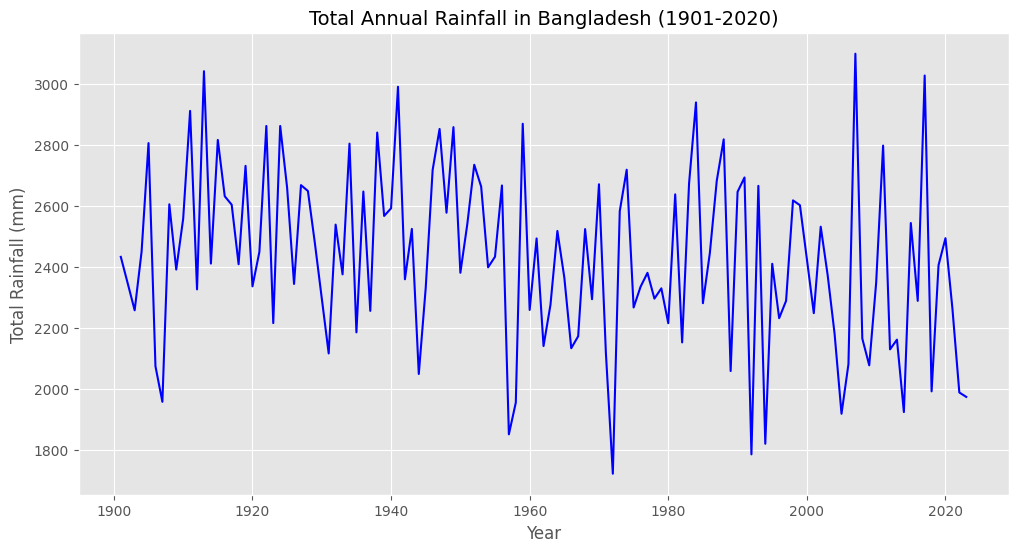

In [ ]:
# Trend Analysis: Annual Total Rainfall
annual_rain = df.groupby('Year')['Rainfall'].sum().reset_index()
plt.figure(figsize=(12, 6))
sns.lineplot(data=annual_rain, x='Year', y='Rainfall', color='blue')
plt.title('Total Annual Rainfall in Bangladesh (1901-2020)', fontsize=14)
plt.xlabel('Year')
plt.ylabel('Total Rainfall (mm)')
plt.show()

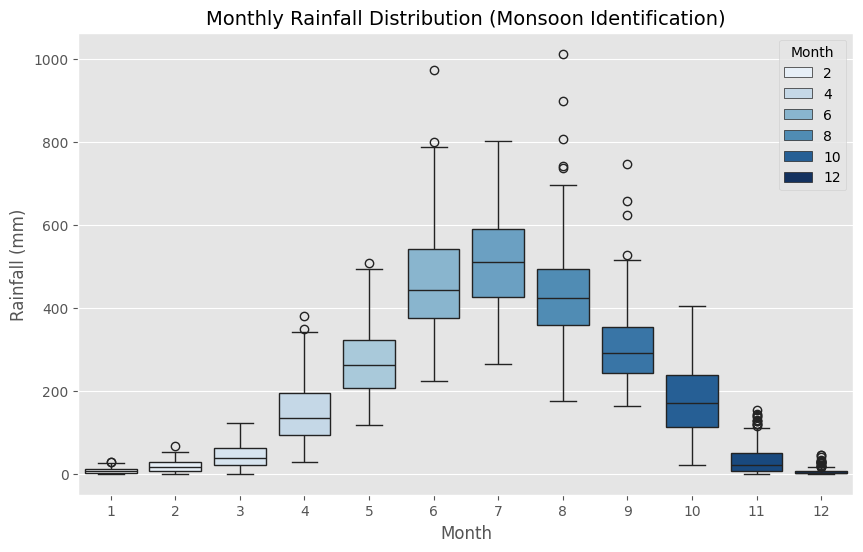

In [ ]:
# Seasonal Analysis: Rainfall by Month
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Month', y='Rainfall',hue='Month',palette='Blues')
plt.title('Monthly Rainfall Distribution (Monsoon Identification)', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Rainfall (mm)')
plt.show()

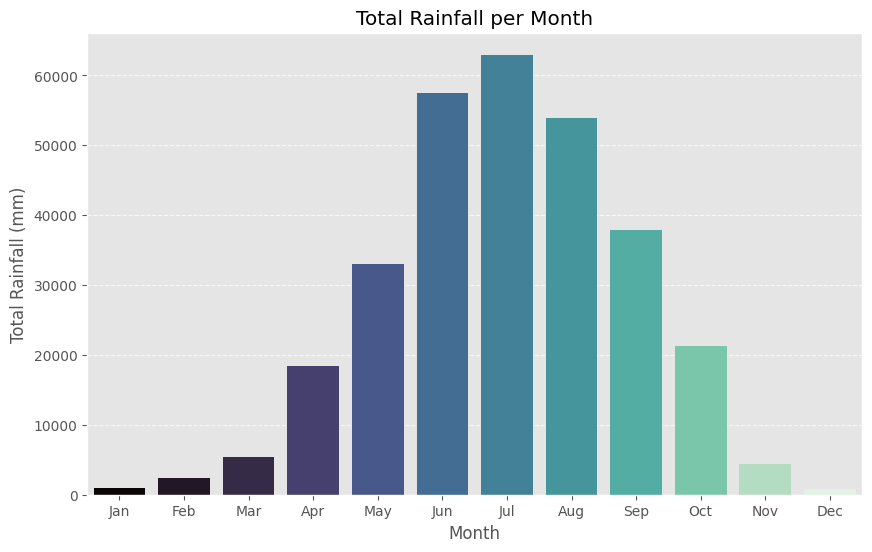

In [ ]:
monthly_rainfall = df.groupby('Month')['Rainfall'].sum().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(x='Month', y='Rainfall', data=monthly_rainfall, hue='Month', palette='mako', legend=False)
plt.title('Total Rainfall per Month')
plt.xlabel('Month')
plt.ylabel('Total Rainfall (mm)')
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

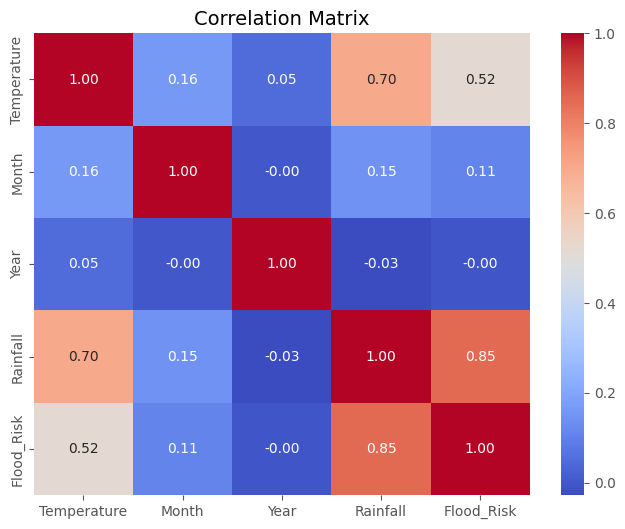

In [ ]:
# 3. Correlation Matrix
plt.figure(figsize=(8, 6))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix', fontsize=14)
plt.show()

In [ ]:
df['Flood_Risk'].value_counts()

,count
Flood_Risk,
0,1021
1,453


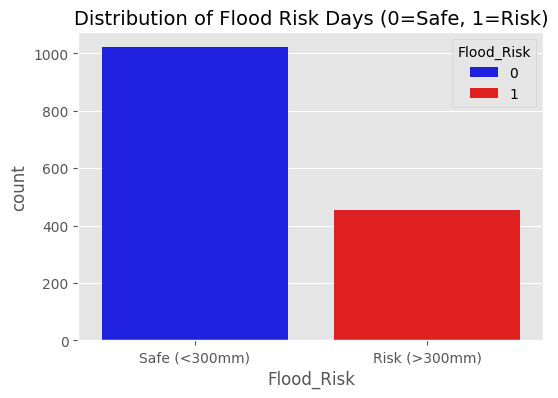

In [ ]:
# Visualize Flood Risk Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Flood_Risk', data=df, hue='Flood_Risk', palette=['blue', 'red'])
plt.title('Distribution of Flood Risk Days (0=Safe, 1=Risk)', fontsize=14)
plt.xticks([0, 1], ['Safe (<300mm)', 'Risk (>300mm)'])
plt.show()

In [ ]:
df.describe()

,Temperature,Month,Year,Rainfall,Flood_Risk
count,1474.000000,1474.000000,1474.000000,1474.000000,1474.000000
mean,25.066443,6.493216,1961.917232,202.817120,0.307327
std,3.701075,3.450595,35.470764,200.780134,0.461543
min,15.925161,1.000000,1901.000000,0.000000,0.000000
25%,22.121579,3.250000,1931.000000,19.382328,0.000000
50%,27.012950,6.000000,1962.000000,146.412000,0.000000
75%,28.032675,9.000000,1993.000000,347.571000,1.000000
max,29.526000,12.000000,2023.000000,1012.020000,1.000000


In [ ]:
X = df[['Month', 'Year']]
y_reg = df[['Rainfall', 'Temperature']]
y_class = df['Flood_Risk']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X, y_reg, test_size=0.2, random_state=42)

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(X, y_class, test_size=0.2, random_state=42)

In [ ]:
print("Training Regression Model...")
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train_reg, y_train_reg)

y_pred_reg = model.predict(X_test_reg)

r2 = r2_score(y_test_reg, y_pred_reg)
print(f"Regression Model Accuracy (R-squared): {r2:.2f}")

Training Regression Model...
Regression Model Accuracy (R-squared): 0.86


In [ ]:
print("\nTraining Classification Model...")
class_model = RandomForestClassifier(n_estimators=100, random_state=42)
class_model.fit(X_train_class, y_train_class)

y_class_pred = class_model.predict(X_test_class)
accuracy = accuracy_score(y_test_class, y_class_pred)
print(f" Classification Model Accuracy: {accuracy*100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test_class, y_class_pred))


Training Classification Model...
 Classification Model Accuracy: 89.15%

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.91      0.92       206
           1       0.80      0.85      0.83        89

    accuracy                           0.89       295
   macro avg       0.87      0.88      0.87       295
weighted avg       0.89      0.89      0.89       295



In [ ]:
print("--- ENTER FORECAST DATE ---")

while True:
    try:
        user_month = int(input("Enter Month (1-12): "))
        user_year = int(input("Enter Year (e.g., 2025): "))

        if not (1 <= user_month <= 12):
            print("Error: Month must be between 1 and 12. Please try again!\n")
        elif not (1901 <= user_year <= 9999):
            print("Error: Year must be a four-digit number between 1901 and 9999. Please try again!\n")
        else:
            break
    except ValueError:
        print("Error: Please enter valid numbers for Month and Year!\n")


input_data = pd.DataFrame([[user_month, user_year]], columns=['Month', 'Year'])

prediction = model.predict(input_data)

pred_rain = prediction[0][0]
pred_temp = prediction[0][1]


print("\n" + "="*30)
print(f"FORECAST REPORT FOR: {user_month}/{user_year}")
print("="*30)
print(f"Predicted Temperature: {pred_temp:.2f} °C")
print(f"Predicted Rainfall:    {pred_rain:.2f} mm")


if pred_rain > 300:
    print("\n WARNING: HIGH FLOOD RISK DETECTED!")
    print("   (Rainfall exceeds 300mm danger threshold)")
else:
    print("\n Status: Safe (No Flood Risk)")

--- ENTER FORECAST DATE ---
Enter Month (1-12): 7
Enter Year (e.g., 2025): 2031

FORECAST REPORT FOR: 7/2031
Predicted Temperature: 28.57 °C
Predicted Rainfall:    350.85 mm

   (Rainfall exceeds 300mm danger threshold)


### Deep Learning (ANN)

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

In [ ]:
# Define Inputs and Outputs
X_ann = df[['Month', 'Year']].values
y_ann = df[['Rainfall', 'Temperature']].values

In [ ]:
# SCALE THE DATA (Crucial Step for ANN)
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X_ann)


scaler_y = MinMaxScaler()
y_scaled = scaler_y.fit_transform(y_ann)

In [ ]:
X_train_ann, X_test_ann, y_train_ann, y_test_ann = train_test_split(
    X_scaled, y_scaled, test_size=0.2, random_state=42
)

print("Data Prepared for ANN!")
print(f"Training Shape: {X_train_ann.shape}")

Data Prepared for ANN!
Training Shape: (1179, 2)


In [ ]:
# BUILD ARCHITECTURE
model_ann = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=[2]),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(2)
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model_ann.compile(
    optimizer='adam',  # The best optimizer for standard problems
    loss='mse',        # Mean Squared Error (minimizes the error)
)

In [ ]:
print("Training Fixed Neural Network...")
history = model_ann.fit(
    X_train_ann, y_train_ann,
    validation_data=(X_test_ann, y_test_ann),
    epochs=150,
    batch_size=32,
    verbose=0
)
print("Training Complete!")

Training Fixed Neural Network...
Training Complete!


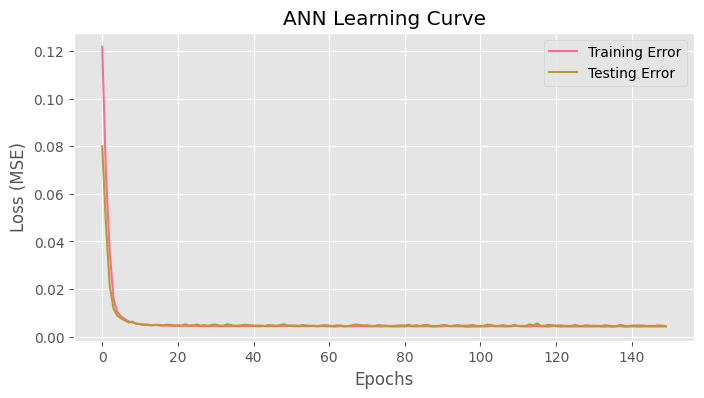

In [ ]:
# Visualize Learning Curve (Optional but good for report)
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training Error')
plt.plot(history.history['val_loss'], label='Testing Error')
plt.title('ANN Learning Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.show()

In [ ]:
y_pred_scaled = model_ann.predict(X_test_ann)
y_pred_real = scaler_y.inverse_transform(y_pred_scaled)
y_test_real = scaler_y.inverse_transform(y_test_ann)

r2_rain = r2_score(y_test_real[:, 0], y_pred_real[:, 0])
r2_temp = r2_score(y_test_real[:, 1], y_pred_real[:, 1])

print(f"Accuracy (R2): Rain={r2_rain:.2f}, Temp={r2_temp:.2f}")



10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
📊 Accuracy (R2): Rain=0.83, Temp=0.97


In [ ]:
print("\n---  NEURAL NETWORK FORECAST ---")
try:
    user_month = int(input("Enter Month (1-12): "))
    user_year = int(input("Enter Year (e.g., 2026): ")) # Use a closer year!
except:
    user_month, user_year = 7, 2026

input_data = scaler_X.transform([[user_month, user_year]])

pred_scaled = model_ann.predict(input_data)
pred_result = scaler_y.inverse_transform(pred_scaled)

rain_out = pred_result[0][0]
temp_out = pred_result[0][1]

if rain_out < 0: rain_out = 0

print(f"\nFor {user_month}/{user_year}:")
print(f" Rain: {rain_out:.2f} mm")
print(f" Temp: {temp_out:.2f} °C")

if rain_out > 300:
    print(" ALERT: High Flood Risk!")
else:
    print(" Status: Safe")


---  NEURAL NETWORK FORECAST ---
Enter Month (1-12): 7
Enter Year (e.g., 2026): 2031
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step

For 7/2031:
 Rain: 376.72 mm
 Temp: 28.42 °C
 ALERT: High Flood Risk!


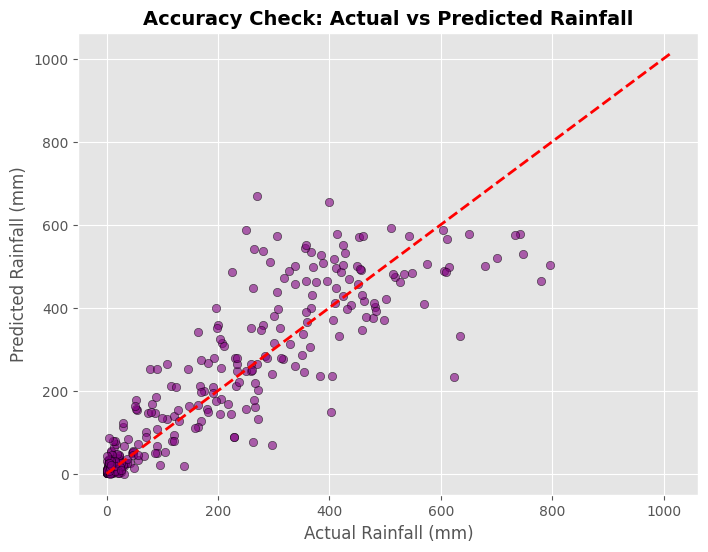

In [ ]:
# ACTUAL VS PREDICTED SCATTER (Accuracy Check)
rf_pred = rf_model.predict(X_test_rf)

plt.figure(figsize=(8, 6))
plt.scatter(y_test_rf[:, 0], rf_pred[:, 0], alpha=0.6, color='purple', edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2) # Diagonal line
plt.title('Accuracy Check: Actual vs Predicted Rainfall', fontsize=14, fontweight='bold')
plt.xlabel('Actual Rainfall (mm)')
plt.ylabel('Predicted Rainfall (mm)')
plt.grid(True)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


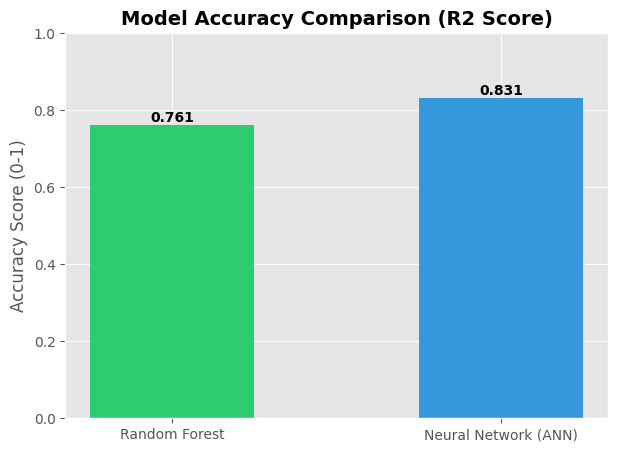

In [ ]:
# MODEL COMPARISON BAR CHART (Scorecard)

rf_r2 = r2_score(y_test_rf[:, 0], rf_pred[:, 0])
ann_pred_scaled = model_ann.predict(X_test_ann)
ann_pred = scaler_y.inverse_transform(ann_pred_scaled)
ann_r2 = r2_score(scaler_y.inverse_transform(y_test_ann)[:, 0], ann_pred[:, 0])

models = ['Random Forest', 'Neural Network (ANN)']
scores = [rf_r2, ann_r2]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, scores, color=['#2ecc71', '#3498db'], width=0.5)
plt.ylim(0, 1.0)
plt.title('Model Accuracy Comparison (R2 Score)', fontsize=14, fontweight='bold')
plt.ylabel('Accuracy Score (0-1)')


for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, round(yval, 3), ha='center', fontweight='bold')


In [ ]:
#  FUTURE DIVERGENCE
future_years = np.arange(2024, 2031)
future_X = np.column_stack((np.full(len(future_years), 7), future_years))

rf_future = rf_model.predict(future_X)[:, 0]

In [ ]:
# ANN Predict
future_X_scaled = scaler_X.transform(future_X)
ann_future_scaled = model_ann.predict(future_X_scaled)
ann_future = scaler_y.inverse_transform(ann_future_scaled)[:, 0]




1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


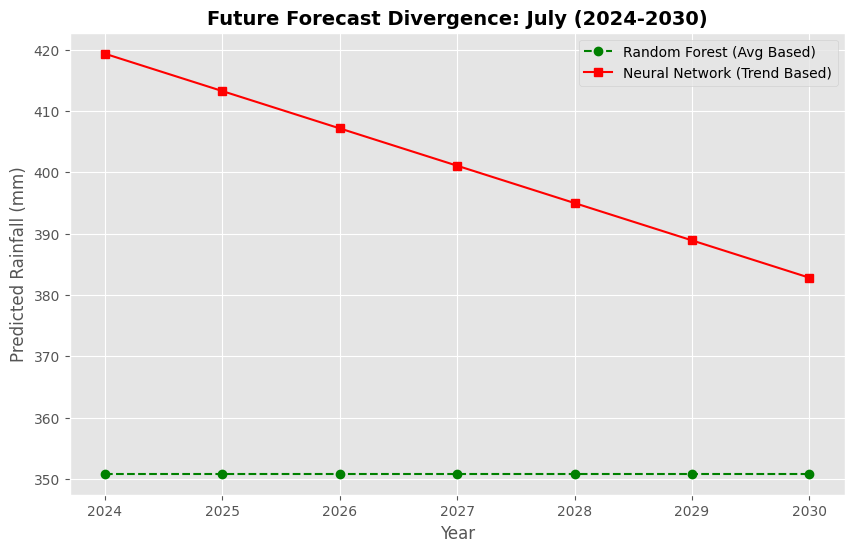

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(future_years, rf_future, marker='o', linestyle='--', color='green', label='Random Forest (Avg Based)')
plt.plot(future_years, ann_future, marker='s', linestyle='-', color='red', label='Neural Network (Trend Based)')

plt.title('Future Forecast Divergence: July (2024-2030)', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Predicted Rainfall (mm)')
plt.legend()
plt.grid(True)